In [2]:
import sys
import os
import json
import torch
import pandas as pd
import random
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


# %%
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    os.chdir("/Volumes/T7-storage/NOFE/dMRI/scripts/" )
else:
    device = torch.device("cpu")
print(f'using Device: {device}')

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, setup_device, get_output_affinities

from dataset_utilities import (
    GraphLMDBWriter,
    #GraphLMDBReader,
)


using Device: mps


In [3]:
os.system("rsync -r springfield:~/new/NOFE/dMRI/trained_models/* ../trained_models/")

** WARNING: connection is not using a post-quantum key exchange algorithm.
** This session may be vulnerable to "store now, decrypt later" attacks.
** The server may need to be upgraded. See https://openssh.com/pq.html


0

In [4]:
# choose data
model_type = 'regular'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/dMRI/scripts/")
from utilities_dMRI import dMRI_Graph_Generator as Data_Generator


# Paths
trained_models_path = project_root / 'dMRI' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'dMRI' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if Path(f).suffix == ".pth":
        print(f'[{i}] {f}')


using Device: mps
Available models:

[0] slim_mask_2026-04-29_t14-39-20.pth
[1] slim_2026-04-29_t11-00-02.pth
[3] base_mask_2026-04-29_t20-51-24.pth
[4] base_2026-04-29_t10-13-29.pth
[5] base-2026-03-17_t17-43-50.pth
[6] base-2026-03-17_t17-37-43.pth
[7] base-2026-03-17_t11-32-32.pth
[8] base-2026-03-17_t10-42-12.pth
[9] base-2026-03-14_t11-51-07.pth


In [6]:
# Set model ID
model_id = 'base_mask_2026-04-29_t20-51-24'



# ---------------------------------------------------------------------------
if model_id.endswith('.pth'):
    model_id = model_id[:-4]

# Load full configuration (includes model, dataset, and training configs)
config_path = f'{training_logs_path}/configs/{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  mode: regular
  model_config_path: dMRI/configurations/regular/model_configs/base.json
  dataset_id: base
  dataset_path: dMRI/datasets/regular
  epochs: 100
  learning_rate: 0.0005
  scheduler_step: 5
  scheduler_gamma: 0.9
  random_seed: 42
  use_gradient_clipping: False
  track_gradients: False
  checkpoint_every: 5
  width: 32
  ker_width: 32
  depth: 3
  node_features: 288
  edge_attr: 7
  out_width: 3
  data_folder_path: ../../../dMRI/
  dataset_save_path: ../datasets/regular/
  N: 10000
  k: 10
  perplexity: 10
  sampling_method: random
  train_samples_per_file: 50
  test_samples_per_file: 20
  feature_mode: channel_only
  sigma_method: variance
\Training completed 21 epochs
Final training loss: 428.6253
Final validation loss: 384.5274


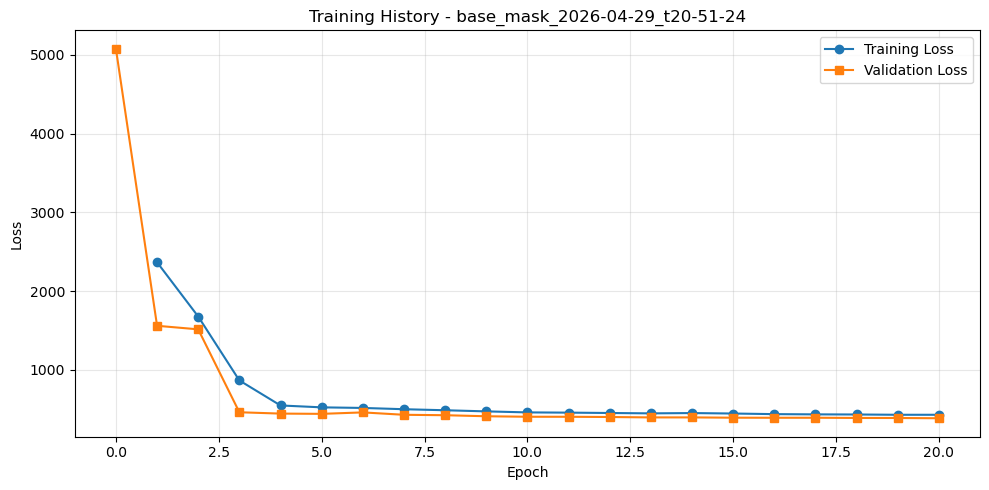

In [7]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
model = KernelNN(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    in_width=config['node_features'],
    out_width=config['out_width']
).to(device)

# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: base_mask_2026-04-29_t20-51-24
Total parameters: 45,507


In [9]:
globals().update(config)

In [10]:
Generator = Data_Generator(data_path)
Generator.load_data('../data/100206/T1w/Diffusion/')

True

In [11]:
print('generate data')
N=30000
graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode)
sample = graph.to(device)

generate data


/Volumes/T7-storage/NOFE/src/generator_utility.py:527: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)


In [12]:
print('predict results')
output = model(sample).detach().cpu().numpy()

predict results


In [13]:
import napari

In [14]:
coords = graph.normed_coords.detach().cpu().numpy()
p1 = np.percentile(output, 1, axis=0)
p99 = np.percentile(output, 99, axis=0)

eps = 1e-8
RGB_brain = (output - p1) / (p99 - p1 + eps)

RGB_brain = np.clip(RGB_brain, 0, 1)

In [13]:
viewer = napari.Viewer(ndisplay=3)
viewer.add_points(coords, face_color=RGB_brain, size=0.02)

<Points layer 'coords' at 0x3199f5cf0>

In [ ]:
from scipy.interpolate import griddata

grid_res = 100  # or higher for more detail
x = np.linspace(0, 1, grid_res)
y = np.linspace(0, 1, grid_res)
z = np.linspace(0, 1, grid_res)
X, Y, Z = np.meshgrid(x, y, z, indexing='ij')
grid_points = np.vstack([X.ravel(), Y.ravel(), Z.ravel()]).T

# Interpolate each channel
R = griddata(coords, RGB_brain[:, 0], grid_points, method='linear', fill_value=0).reshape(grid_res, grid_res, grid_res)
G = griddata(coords, RGB_brain[:, 1], grid_points, method='linear', fill_value=0).reshape(grid_res, grid_res, grid_res)
B = griddata(coords, RGB_brain[:, 2], grid_points, method='linear', fill_value=0).reshape(grid_res, grid_res, grid_res)

RGB_grid = np.stack([R, G, B], axis=-1)

viewer = napari.Viewer(ndisplay=3)
viewer.add_image(RGB_grid, rgb=True)

<Image layer 'RGB_grid' at 0x31c95d5a0>

: 